In [1]:
import numpy as np
import cv2
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [2]:
# definindo as dimensoes das imagens
# 288x288 pois no modelo com resnet será necessario
# na ttentativa de usar o modelo resnet, ao fazer a divisao nas camadas de pooling o Concatenate estava dandao erro na divisao ppois a imagem estava em 300x300, entao ajustei para 288
height_img = 288
width_img = 288
canais = 3
# imgs originais são RGB

In [3]:
list_path_img = []
# lista de dirs, onde estao as imagens
list_path_img.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice Leaf Disease Images/Bacterialblight')
list_path_img.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice Leaf Disease Images/Blast')
list_path_img.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice Leaf Disease Images/Brownspot')
list_path_img.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice Leaf Disease Images/Tungro')

In [4]:
list_path_mask = []
# dirs das mascaras
list_path_mask.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice_Leaf_Disease_Segmentation_Masks/mask-vesrion1/Bacterialblight')
list_path_mask.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice_Leaf_Disease_Segmentation_Masks/mask-vesrion1/Blast')
list_path_mask.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice_Leaf_Disease_Segmentation_Masks/mask-vesrion1/Brownspot')
list_path_mask.append('/home/beuren/Documentos/segmentation_rice/raw/data/Rice_Leaf_Disease_Segmentation_Masks/mask-vesrion1/Tungro')

In [5]:
samples = []  # caminho_img, caminho_mask, classe_id
for classe_id, (path_img, path_mask) in enumerate(zip(list_path_img, list_path_mask)):
    # numero da pasta da classe, e para cada caminho que esta na lista de imagens e mascaras
    # pega os nomes dos arquivos na pasta de imagem
    nomes = sorted(next(os.walk(path_img))[2])
    for nome in nomes:
        #para cada nome pega o path exato de cada imagem
        img_path = os.path.join(path_img, nome)
        mask_path = os.path.join(path_mask, nome)
        # pega o mesmo nome do arquivo de imagem pas para a pasta de mascaras
        # SO FUNCIONA PQ OS NOMES DAS IMAGENS E MASCARAS SAO IGUAIS
        samples.append((img_path, mask_path, classe_id))
        # adiciona a lista, a tupla que correspote a psta da imagem, pasta da mascara e a classe


In [6]:
len(samples)
# verificando o tamnho dq lista

5932

In [7]:
data_img=np.zeros((len(samples), height_img, width_img,canais), dtype=np.uint8)
# cria uma matriz de quatro dimensoes, quantidade de imgs, altura da imagem, largura e quantidade de canais
data_mask = np.zeros((len(samples),height_img,width_img,1), dtype=np.uint8)
# matriz de quatro dimensoes para as mascaras mas com 1 canal

In [8]:
data_img.shape, data_mask.shape
# conferindo o tamanho da base de imagens e mascaras

((5932, 288, 288, 3), (5932, 288, 288, 1))

In [9]:
for i, (img_path,mask_path, classe_id) in tqdm(enumerate(samples),total=len(samples)):
    # para cada iteração vai ler a imagem e redimensionar para o padrão definido
    # utilizei mais por garantia de que todas estejam no mesmo tamanho
    img = cv2.imread(img_path)
    img =cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    # colocando em rgb, pois o imread coloca em bgr
    img = cv2.resize(img,(height_img, width_img))
    data_img[i] = img

    mask = cv2.imread(mask_path)
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
    # transforma a imagem em cinza
    mask = cv2.resize(mask, (height_img, width_img), interpolation=cv2.INTER_NEAREST) # o INTER_NEAREST garante que ao redimensionar nao seja atribuido um pixel com um valor quebrado tipo 127, mas sim 0 ou 1, representando 1 a lesão e 0 o fundo
    # redimensiona a mascara para o tamanho esperado e adiciona uma dimensao
    mask_bin = (mask > 127).astype(np.uint8)
    # compara cada pixel com 127, se maior atribui 1 e se menor atribui 0
    mask = np.where(mask_bin == 1, classe_id, 4).astype(np.uint8)
    # para cada pixel verifica se 1 coloca a classe respectiva a sua lesao, e se 0 coloca 4
    mask = np.expand_dims(mask, axis=-1)
    # adiciona uma dimensao no final
    data_mask[i] = mask
    # atribuindo a mascara para sua respectiva posição

    # para a segmentação semantica multiclasse, foi necessario fazer uma categorização de pixels
    # onde para cada pixel da mascara correspondente a lesao 3 por exemplo, todos os pixels daquela mascara receberão o rotulo 3

data_mask.shape, data_img.shape

100%|██████████| 5932/5932 [00:06<00:00, 882.93it/s] 


((5932, 288, 288, 1), (5932, 288, 288, 3))

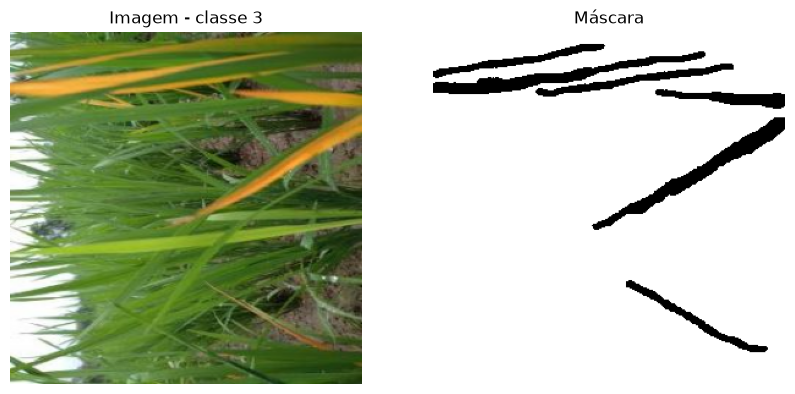

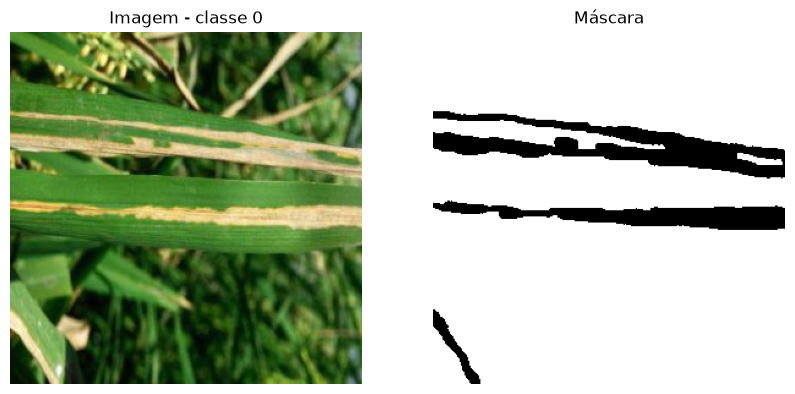

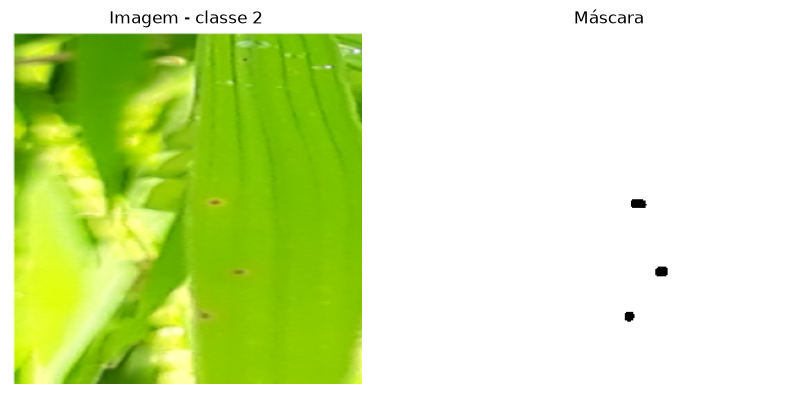

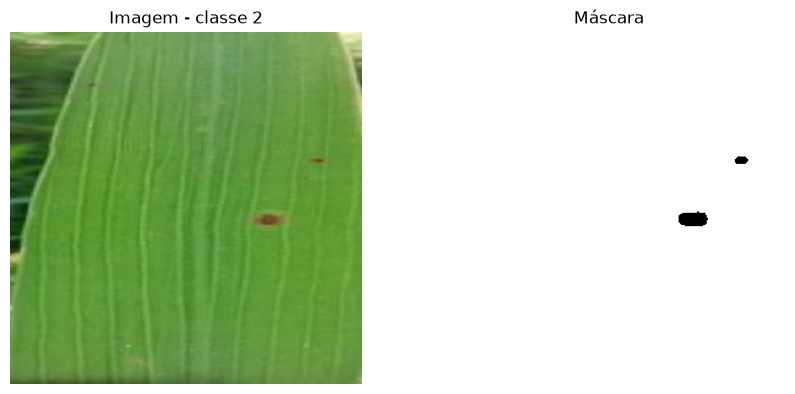

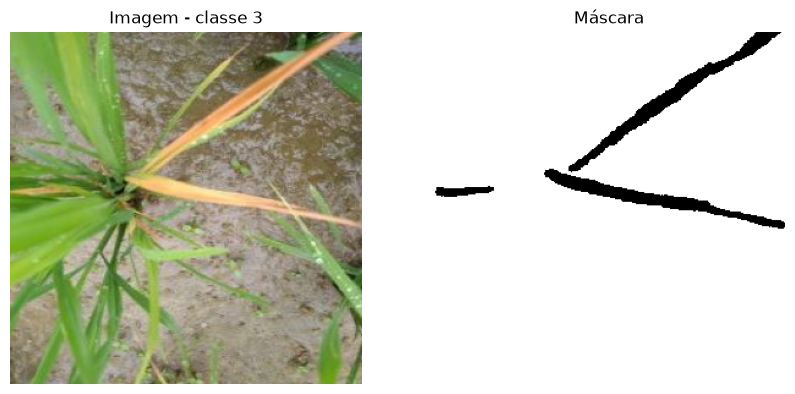

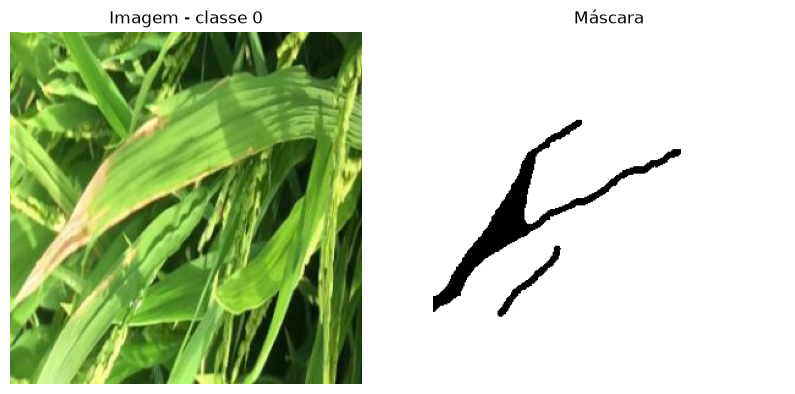

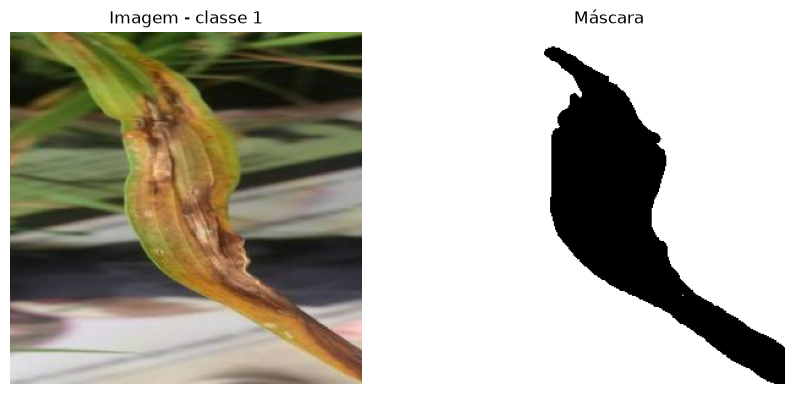

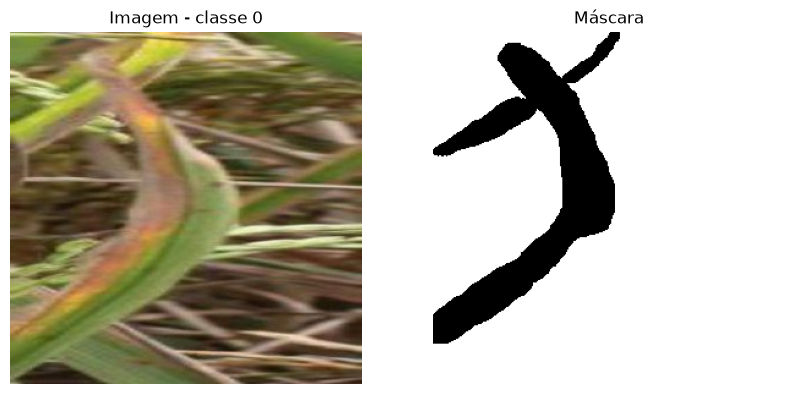

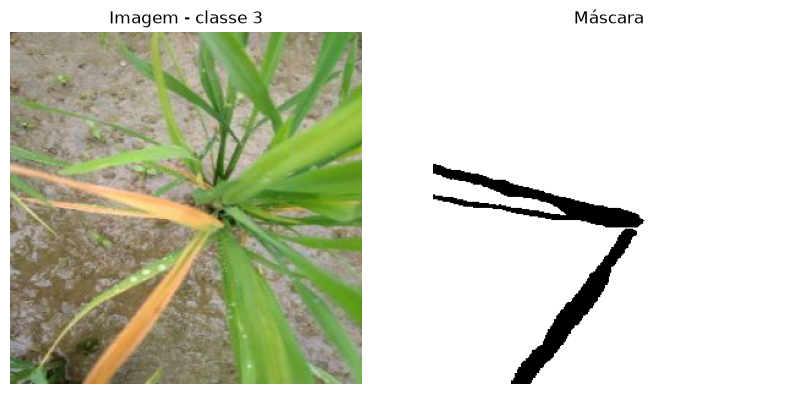

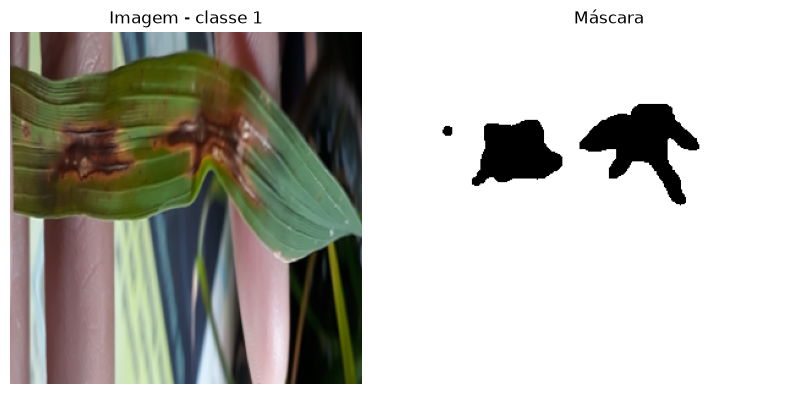

In [10]:
# verificando se as mascaras correspondem a suas imagens com amostras aleatórias
for i in range(10):
    id_img = np.random.randint(1,5900)
    fig = plt.figure(figsize=(10,7))

    fig.add_subplot(1,2,1)
    plt.imshow(data_img[id_img])
    plt.axis('off')
    plt.title(f'Imagem - classe {samples[id_img][2]}')


    fig.add_subplot(1,2,2)
    plt.imshow(np.squeeze(data_mask[id_img]), cmap='gray')
    plt.axis('off')
    plt.title('Máscara')

In [11]:
classes = [c[2] for c in samples]
# pega em ordem todas as classes
x_train,x_val, y_train, y_val= train_test_split(data_img,data_mask,test_size=0.2,stratify=classes)
# separando os dados de treino e validação, x são as imagens e y as mascaras
# o stratify garante que a divisao de treino e validation tenham a mesma proporção de diferentes classes

In [12]:
x_train.shape

(4745, 288, 288, 3)

In [13]:
y_train.shape

(4745, 288, 288, 1)

In [14]:
# salvando as divisões em arrays numpy
np.save('/home/beuren/Documentos/segmentation_rice/processed/train/x_train.npy', x_train)
np.save('/home/beuren/Documentos/segmentation_rice/processed/train/y_train.npy', y_train)
np.save('/home/beuren/Documentos/segmentation_rice/processed/train/x_val.npy', x_val)
np.save('/home/beuren/Documentos/segmentation_rice/processed/train/y_val.npy', y_val)

### DADOS DE TESTE

In [15]:
list_path_test = []
# lista de dirs, onde estao as imagens
list_path_test.append('/home/beuren/Documentos/segmentation_rice/raw/data/A Rice Leaf Disease Image Dataset for Multi-Class/bacterial_leaf_blight')
list_path_test.append('/home/beuren/Documentos/segmentation_rice/raw/data/A Rice Leaf Disease Image Dataset for Multi-Class/leaf_blast')
list_path_test.append('/home/beuren/Documentos/segmentation_rice/raw/data/A Rice Leaf Disease Image Dataset for Multi-Class/brown_spot')
list_path_test.append('/home/beuren/Documentos/segmentation_rice/raw/data/A Rice Leaf Disease Image Dataset for Multi-Class/tungro')

In [16]:
list_ = []  
for classe_id, path_test in enumerate(list_path_test):
    # numero da classe com base na numeração das pastas, e pega o patj de cada uma delas
    nomes = sorted(next(os.walk(path_test))[2])
    for n in nomes:
        img_test = os.path.join(path_test, n)
        list_.append((img_test, classe_id))


In [17]:
len(list_)

2623

In [18]:
data_test=np.zeros((len(list_), height_img, width_img,canais), dtype=np.uint8)


In [19]:
list_[0]

('/home/beuren/Documentos/segmentation_rice/raw/data/A Rice Leaf Disease Image Dataset for Multi-Class/bacterial_leaf_blight/Symptoms-of-bacterial-leaf-blight-disease-in-rice-caused-by-Xanthomonas-oryzae-pv.png',
 0)

In [20]:
for i, (path_test, classe_id) in tqdm(enumerate(list_),total=len(list_)):
    # para cada iter será colocado no padrão definido de imagem
    img = cv2.imread(path_test)
    img =cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    img = cv2.resize(img,(height_img, width_img))
    data_test[i] = img

100%|██████████| 2623/2623 [00:35<00:00, 74.84it/s] 


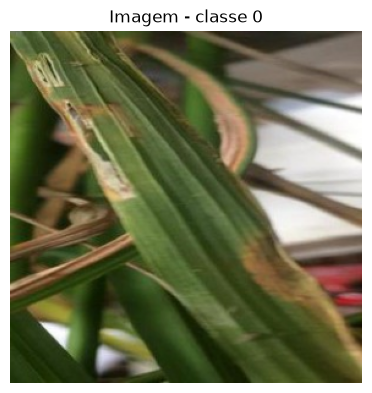

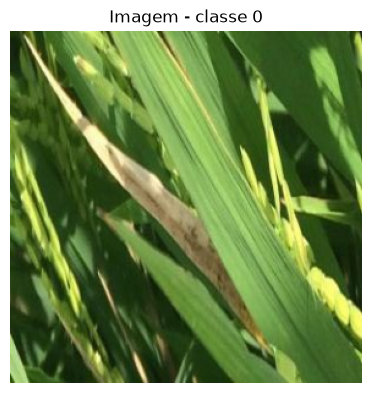

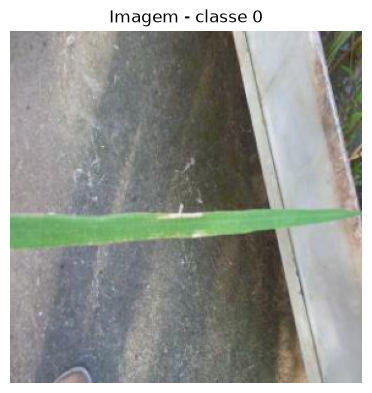

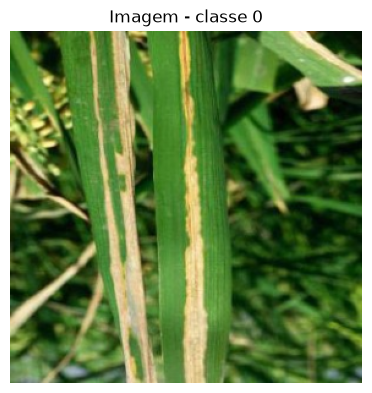

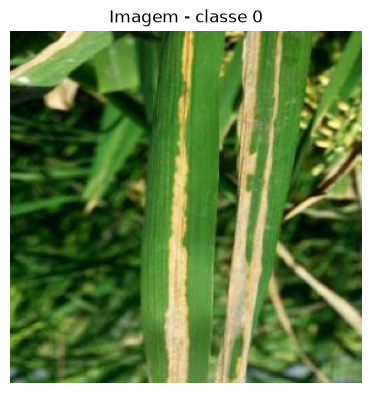

In [21]:
# imagens e suas classes
for i in range(5):
    id_img = np.random.randint(1,1000)
    fig = plt.figure(figsize=(10,7))

    fig.add_subplot(1,2,1)
    plt.imshow(data_img[id_img])
    plt.axis('off')
    plt.title(f'Imagem - classe {list_[id_img][1]}')

In [22]:
classes_test = np.array([c[1] for c in list_])
# pega todas as classes dos dados de teste(cada uma associada a sua imagem)

In [23]:
np.save('/home/beuren/Documentos/segmentation_rice/processed/test/x_test.npy', data_test)
np.save('/home/beuren/Documentos/segmentation_rice/processed/test/y_test.npy', classes_test)